In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Загружаем данные Iris (3 класса, 4 признака)
iris = load_iris()
X, y = iris.data, iris.target
feature_names = iris.feature_names
class_names = iris.target_names

print("Информация о данных:")
print(f"Количество классов: {len(class_names)}")
print(f"Названия классов: {class_names}")
print(f"Количество признаков: {len(feature_names)}")
print(f"Названия признаков: {feature_names}")
print(f"Размерность данных: {X.shape}")

Информация о данных:
Количество классов: 3
Названия классов: ['setosa' 'versicolor' 'virginica']
Количество признаков: 4
Названия признаков: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Размерность данных: (150, 4)


In [2]:
# Стандартизируем данные для корректного сравнения коэффициентов
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Обучаем LDA модель
lda = LinearDiscriminantAnalysis()
lda.fit(X_scaled, y)

print("\n=== ПАРАМЕТРЫ LDA МОДЕЛИ ===")
print(f"Количество дискриминантных осей: {lda.coef_.shape[0]}")
print(f"Форма коэффициентов: {lda.coef_.shape}")  # (n_classes-1, n_features)
print(f"Форма intercept: {lda.intercept_.shape}")


=== ПАРАМЕТРЫ LDA МОДЕЛИ ===
Количество дискриминантных осей: 3
Форма коэффициентов: (3, 4)
Форма intercept: (3,)


In [3]:
# Создаем DataFrame для удобного анализа коэффициентов
coef_df = pd.DataFrame(
    lda.coef_,
    columns=feature_names,
    index=[f'LD{i+1}' for i in range(lda.coef_.shape[0])]
)

print("\n=== КОЭФФИЦИЕНТЫ ДИСКРИМИНАНТНЫХ ФУНКЦИЙ ===")
print(coef_df)

print("\n=== INTERCEPT (СВОБОДНЫЕ ЧЛЕНЫ) ===")
for i, intercept in enumerate(lda.intercept_):
    print(f"LD{i+1}: {intercept:.4f}")


=== КОЭФФИЦИЕНТЫ ДИСКРИМИНАНТНЫХ ФУНКЦИЙ ===
     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
LD1           5.211578          5.273453         -29.815608        -15.778857
LD2          -1.263701         -1.901001           8.261573          2.326624
LD3          -3.947878         -3.372451          21.554036         13.452234

=== INTERCEPT (СВОБОДНЫЕ ЧЛЕНЫ) ===
LD1: -30.0595
LD2: -3.0289
LD3: -17.9490


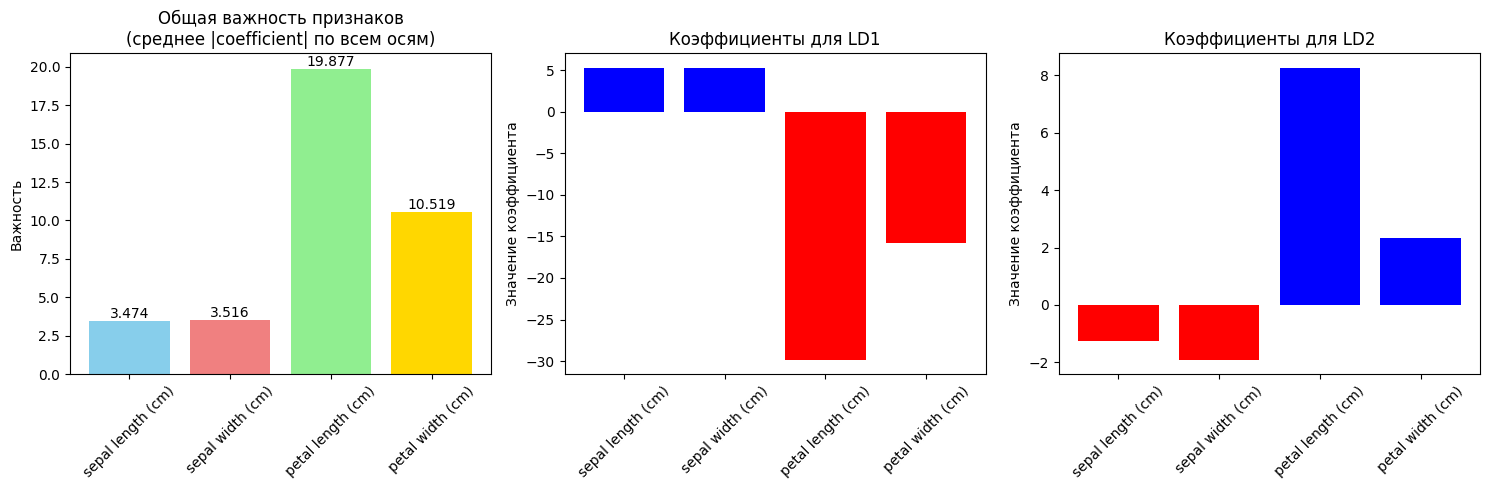

In [4]:
# Вычисляем общую важность признаков (среднее абсолютное значение по осям)
feature_importance = np.mean(np.abs(lda.coef_), axis=0)

plt.figure(figsize=(15, 5))

# График 1: Важность признаков
plt.subplot(1, 3, 1)
colors = ['skyblue', 'lightcoral', 'lightgreen', 'gold']
bars = plt.bar(feature_names, feature_importance, color=colors)
plt.title('Общая важность признаков\n(среднее |coefficient| по всем осям)')
plt.ylabel('Важность')
plt.xticks(rotation=45)

# Добавляем значения на столбцы
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{height:.3f}', ha='center', va='bottom')

# График 2: Коэффициенты по осям LD1
plt.subplot(1, 3, 2)
colors_ld1 = ['blue' if x > 0 else 'red' for x in coef_df.iloc[0]]
bars_ld1 = plt.bar(feature_names, coef_df.iloc[0], color=colors_ld1)
plt.title('Коэффициенты для LD1')
plt.ylabel('Значение коэффициента')
plt.xticks(rotation=45)

# График 3: Коэффициенты по осям LD2
plt.subplot(1, 3, 3)
colors_ld2 = ['blue' if x > 0 else 'red' for x in coef_df.iloc[1]]
bars_ld2 = plt.bar(feature_names, coef_df.iloc[1], color=colors_ld2)
plt.title('Коэффициенты для LD2')
plt.ylabel('Значение коэффициента')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [5]:
print("\n" + "="*60)
print("ДЕТАЛЬНАЯ ИНТЕРПРЕТАЦИЯ КОЭФФИЦИЕНТОВ")
print("="*60)

# Анализ LD1 (первая дискриминантная ось)
print("\n--- LD1 (Основная ось разделения) ---")
ld1_coef = coef_df.iloc[0]
for feature, coef in ld1_coef.items():
    direction = "увеличивает вероятность класса setosa" if coef > 0 else "увеличивает вероятность классов versicolor/virginica"
    print(f"{feature:>25}: {coef:7.3f} -> {direction}")

# Анализ LD2 (вторая дискриминантная ось)
print("\n--- LD2 (Вторая ось разделения) ---")
ld2_coef = coef_df.iloc[1]
for feature, coef in ld2_coef.items():
    direction = "увеличивает вероятность класса virginica" if coef > 0 else "увеличивает вероятность класса versicolor"
    print(f"{feature:>25}: {coef:7.3f} -> {direction}")

print("\n--- ОБЩАЯ ВАЖНОСТЬ ПРИЗНАКОВ ---")
for i, (feature, importance) in enumerate(zip(feature_names, feature_importance)):
    print(f"{feature:>25}: {importance:.3f} (ранг {i+1})")


ДЕТАЛЬНАЯ ИНТЕРПРЕТАЦИЯ КОЭФФИЦИЕНТОВ

--- LD1 (Основная ось разделения) ---
        sepal length (cm):   5.212 -> увеличивает вероятность класса setosa
         sepal width (cm):   5.273 -> увеличивает вероятность класса setosa
        petal length (cm): -29.816 -> увеличивает вероятность классов versicolor/virginica
         petal width (cm): -15.779 -> увеличивает вероятность классов versicolor/virginica

--- LD2 (Вторая ось разделения) ---
        sepal length (cm):  -1.264 -> увеличивает вероятность класса versicolor
         sepal width (cm):  -1.901 -> увеличивает вероятность класса versicolor
        petal length (cm):   8.262 -> увеличивает вероятность класса virginica
         petal width (cm):   2.327 -> увеличивает вероятность класса virginica

--- ОБЩАЯ ВАЖНОСТЬ ПРИЗНАКОВ ---
        sepal length (cm): 3.474 (ранг 1)
         sepal width (cm): 3.516 (ранг 2)
        petal length (cm): 19.877 (ранг 3)
         petal width (cm): 10.519 (ранг 4)


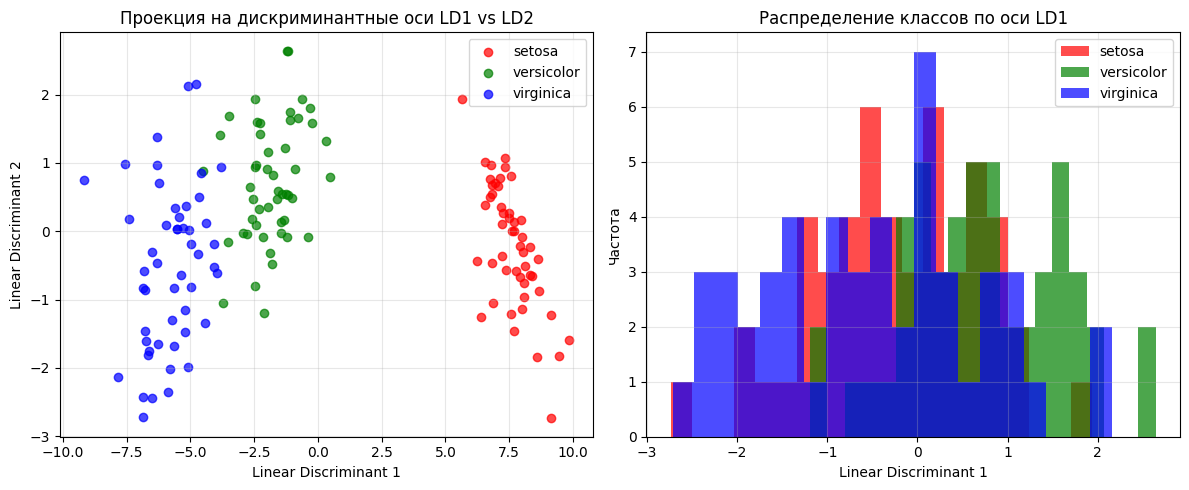

In [ ]:
# Проецируем данные на дискриминантные плоскости
X_lda = lda.transform(X_scaled)

plt.figure(figsize=(12, 5))

# Проекция на LD1 и LD2
plt.subplot(1, 2, 1)
colors = ['red', 'green', 'blue']
for i, class_name in enumerate(class_names):
    plt.scatter(X_lda[y == i, 0], X_lda[y == i, 1], 
                c=colors[i], label=class_name, alpha=0.7)
plt.xlabel('Linear Discriminant 1')
plt.ylabel('Linear Discriminant 2')
plt.title('Проекция на дискриминантные оси LD1 vs LD2')
plt.legend()
plt.grid(True, alpha=0.3)

# Гистограмма распределения по LD1
plt.subplot(1, 2, 2)
for i, class_name in enumerate(class_names):
    plt.hist(X_lda[y == i, 0], bins=20, alpha=0.7, 
             label=class_name, color=colors[i])
plt.xlabel('Linear Discriminant 1')
plt.ylabel('Частота')
plt.title('Распределение классов по оси LD1')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [7]:
print("\n" + "="*60)
print("КАК МОДЕЛЬ ДЕЛАЕТ ПРЕДСКАЗАНИЯ")
print("="*60)

# Возьмем несколько примеров для демонстрации
sample_indices = [0, 50, 100]  # по одному из каждого класса

for idx in sample_indices:
    sample = X_scaled[idx:idx+1]  # берем один образец
    true_class = class_names[y[idx]]
    
    # Вычисляем дискриминантные функции для каждого класса
    decision_scores = lda.decision_function(sample)
    
    print(f"\nОбразец {idx} (истинный класс: {true_class}):")
    print("Результаты дискриминантных функций:")
    for i, class_name in enumerate(class_names):
        print(f"  {class_name:>10}: {decision_scores[0, i]:.3f}")
    
    predicted_class = class_names[lda.predict(sample)[0]]
    print(f"  Предсказанный класс: {predicted_class}")


КАК МОДЕЛЬ ДЕЛАЕТ ПРЕДСКАЗАНИЯ

Образец 0 (истинный класс: setosa):
Результаты дискриминантных функций:
      setosa: 31.336
  versicolor: -17.961
   virginica: -64.413
  Предсказанный класс: setosa

Образец 50 (истинный класс: versicolor):
Результаты дискриминантных функций:
      setosa: -41.155
  versicolor: -0.386
   virginica: -9.496
  Предсказанный класс: versicolor

Образец 100 (истинный класс: virginica):
Результаты дискриминантных функций:
      setosa: -89.239
  versicolor: 9.721
   virginica: 28.480
  Предсказанный класс: virginica
